Nama: Kirana Aripuspa Wardani
NIM: 2404010010
# Preprocessing Data ISPU DKI Jakarta Tahun 2017

## 1. Import library
Kode ini digunakan untuk mengimpor library yang dibutuhkan dalam proses preprocessing data

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

##2. Memuat Dataset dan Inspeksi Awal
Kode ini digunakan untuk mengunggah dataset ISPU DKI Jakarta Tahun 2017, membaca file CSV, dan membuat salinan data untuk proses preprocessing. Selanjutnya, kode menampilkan ukuran dataset serta lima baris pertama untuk melihat struktur data.

In [4]:
try:
    from google.colab import files
    uploaded = files.upload()
    nama_file = list(uploaded.keys())[0]
except ImportError:
    # kalau dijalankan di luar Colab, isi nama file secara manual
    nama_file = "Filedata_Indeks_Standar_Pencemaran_Udara_ISPU_Tahun_2017.csv"

df_raw = pd.read_csv(nama_file, encoding="utf-8-sig")
df = df_raw.copy()

print("Ukuran data:", df.shape)
df.head()

Saving Filedata Indeks Standar Pencemaran Udara ISPU Tahun 2017.csv to Filedata Indeks Standar Pencemaran Udara ISPU Tahun 2017.csv
Ukuran data: (1825, 11)


,periode_data,tanggal,stasiun,pm10,so2,co,o3,no2,max,critical,categori
0,201701,2017-01-01,DKI1 (Bunderan HI),63,34,25,21,2,63,PM10,SEDANG
1,201701,2017-01-02,DKI1 (Bunderan HI),16,32,16,19,1,32,SO2,BAIK
2,201701,2017-01-03,DKI1 (Bunderan HI),18,32,17,20,2,32,SO2,BAIK
3,201701,2017-01-04,DKI1 (Bunderan HI),24,32,22,20,2,32,SO2,BAIK
4,201701,2017-01-05,DKI1 (Bunderan HI),29,32,25,14,2,32,SO2,BAIK


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1825 entries, 0 to 1824
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   periode_data  1825 non-null   int64 
 1   tanggal       1825 non-null   object
 2   stasiun       1825 non-null   object
 3   pm10          1825 non-null   object
 4   so2           1825 non-null   object
 5   co            1825 non-null   object
 6   o3            1825 non-null   object
 7   no2           1825 non-null   object
 8   max           1825 non-null   object
 9   critical      1800 non-null   object
 10  categori      1825 non-null   object
dtypes: int64(1), object(10)
memory usage: 157.0+ KB


In [6]:
print("Jumlah nilai unik per kolom:")
print(df.nunique())
print()
print("Kategori:", df["categori"].value_counts(dropna=False).to_dict())
print("Critical:", df["critical"].value_counts(dropna=False).to_dict())

Jumlah nilai unik per kolom:
periode_data     12
tanggal         365
stasiun           5
pm10            102
so2              54
co               66
o3              149
no2              31
max             143
critical          6
categori          4
dtype: int64

Kategori: {'SEDANG': 1121, 'BAIK': 476, 'TIDAK SEHAT': 198, 'TIDAK ADA DATA': 30}
Critical: {'O3': 1152, 'PM10': 485, 'SO2': 92, 'CO': 65, nan: 25, '---': 5, 'NO2': 1}


##3. Standarisasi Nama Kolom dan Teks
Kode ini digunakan untuk menyeragamkan nama kolom menjadi huruf kecil, memperbaiki nama kolom yang tidak konsisten, serta menghapus spasi berlebih. Teks pada kolom stasiun, critical, dan kategori juga diubah menjadi huruf kapital agar format data lebih seragam.

In [7]:
df.columns = df.columns.str.strip().str.lower()
df = df.rename(columns={"categori": "kategori", "max": "max_ispu"})

for kolom in ["stasiun", "critical", "kategori"]:
    df[kolom] = df[kolom].astype("string").str.strip().str.upper()

print(df.columns.tolist())

['periode_data', 'tanggal', 'stasiun', 'pm10', 'so2', 'co', 'o3', 'no2', 'max_ispu', 'critical', 'kategori']


##4. Menangani Placeholder ---
Kode ini digunakan untuk menghitung jumlah placeholder --- pada setiap kolom, kemudian menggantinya dengan NaN (nilai kosong) agar dapat ditangani pada tahap preprocessing berikutnya.

In [8]:
jumlah_strip = (df == "---").sum()
print("Jumlah '---' per kolom (sebelum diganti):")
print(jumlah_strip[jumlah_strip > 0])

df = df.replace("---", np.nan)

Jumlah '---' per kolom (sebelum diganti):
pm10        115
so2          79
co           95
o3           87
no2          86
max_ispu      5
critical      5
dtype: Int64


##5. Konversi Tipe Data
Kode ini digunakan untuk mengubah kolom tanggal menjadi format tanggal (datetime) dan kolom polutan serta max_ispu menjadi tipe data numerik. Jika ada nilai yang tidak bisa dikonversi, nilai tersebut akan diubah menjadi NaN agar bisa ditangani pada tahap selanjutnya.

In [9]:
polutan = ["pm10", "so2", "co", "o3", "no2"]

df["tanggal"] = pd.to_datetime(df["tanggal"], errors="coerce")
for kolom in polutan + ["max_ispu"]:
    df[kolom] = pd.to_numeric(df[kolom], errors="coerce")

print("Tanggal gagal diparsing:", df["tanggal"].isna().sum())
df.dtypes

Tanggal gagal diparsing: 0


,0
periode_data,int64
tanggal,datetime64[ns]
stasiun,string[python]
pm10,float64
so2,float64
co,float64
o3,float64
no2,float64
max_ispu,float64
critical,string[python]


##6. Pengecekan dan Penghapusan Data Duplikat
Kode ini digunakan untuk menghitung data duplikat secara keseluruhan dan berdasarkan kombinasi kolom tanggal dan stasiun. Setelah itu, data duplikat berdasarkan kombinasi tersebut dihapus agar setiap stasiun hanya memiliki satu catatan untuk setiap tanggal.

In [10]:
print("Baris duplikat penuh:", df.duplicated().sum())
print("Duplikat pada kombinasi (tanggal, stasiun):", df.duplicated(subset=["tanggal", "stasiun"]).sum())

df = df.drop_duplicates(subset=["tanggal", "stasiun"]).reset_index(drop=True)
print("Ukuran data setelah cek duplikat:", df.shape)

Baris duplikat penuh: 0
Duplikat pada kombinasi (tanggal, stasiun): 0
Ukuran data setelah cek duplikat: (1825, 11)


##7. Analisis Missing Value
Kode ini digunakan untuk menghitung jumlah dan persentase nilai kosong pada setiap kolom. Hasilnya ditampilkan dalam bentuk tabel dan diagram batang agar kolom yang memiliki missing value dapat diketahui sebelum dilakukan penanganan.

,jumlah_missing,persen
pm10,115,6.30
so2,79,4.33
co,95,5.21
o3,87,4.77
no2,86,4.71
max_ispu,5,0.27
critical,30,1.64


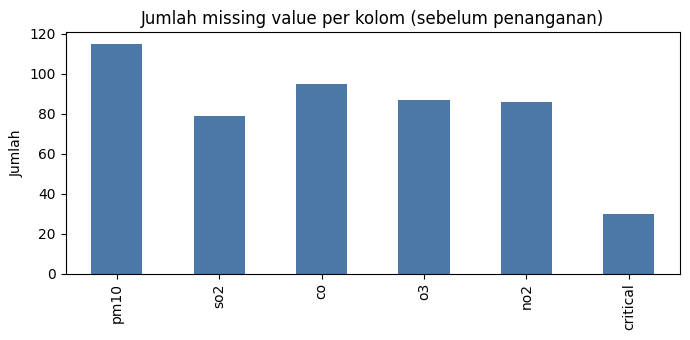

In [11]:
missing = df.isna().sum()
persen = (missing / len(df) * 100).round(2)
ringkasan = pd.DataFrame({"jumlah_missing": missing, "persen": persen})
display(ringkasan[ringkasan["jumlah_missing"] > 0])

ringkasan.loc[polutan + ["critical"], "jumlah_missing"].plot(kind="bar", figsize=(7, 3.5), color="#4C78A8")
plt.title("Jumlah missing value per kolom (sebelum penanganan)")
plt.ylabel("Jumlah")
plt.tight_layout()
plt.show()

##8. Menghapus Baris Tanpa Data
Kode ini digunakan untuk mengidentifikasi dan menghapus baris dengan kategori TIDAK ADA DATA, terutama ketika seluruh nilai polutannya kosong. Setelah penghapusan, jumlah data dan missing value yang tersisa diperiksa kembali.

In [12]:
tanpa_data = df["kategori"] == "TIDAK ADA DATA"
print("Baris TIDAK ADA DATA:", tanpa_data.sum())
print("Semua polutan kosong pada baris itu:", df.loc[tanpa_data, polutan].isna().all(axis=1).all())

df = df.loc[~tanpa_data].reset_index(drop=True)
print("Ukuran data setelah dibuang:", df.shape)
print()
print("Missing value tersisa:")
print(df.isna().sum()[df.isna().sum() > 0])

Baris TIDAK ADA DATA: 30
Semua polutan kosong pada baris itu: True
Ukuran data setelah dibuang: (1795, 11)

Missing value tersisa:
pm10    85
so2     49
co      65
o3      57
no2     56
dtype: int64


##9. Validasi Konsistensi Kolom Turunan
Kode ini digunakan untuk memeriksa kesesuaian nilai max_ispu, critical, dan kategori dengan hasil perhitungan berdasarkan data polutan. Tujuannya untuk mengetahui apakah nilai ISPU maksimum, polutan tertinggi, dan kategori kualitas udara sudah sesuai dengan data yang tersedia.

In [13]:
def kategori_dari_nilai(x):
    if x <= 50:
        return "BAIK"
    elif x <= 100:
        return "SEDANG"
    elif x <= 199:
        return "TIDAK SEHAT"
    return "SANGAT TIDAK SEHAT"

max_hitung = df[polutan].max(axis=1)
critical_hitung = df[polutan].idxmax(axis=1).str.upper()
kategori_hitung = df["max_ispu"].apply(kategori_dari_nilai)

print("max_ispu cocok dengan max polutan   :", f"{(max_hitung == df['max_ispu']).mean():.1%}")
print("critical cocok dengan polutan tertinggi:", f"{(critical_hitung == df['critical']).mean():.1%}")
print("kategori cocok dengan max_ispu      :", f"{(kategori_hitung == df['kategori']).mean():.1%}")

max_ispu cocok dengan max polutan   : 100.0%
critical cocok dengan polutan tertinggi: 100.0%
kategori cocok dengan max_ispu      : 100.0%


##10. Imputasi Missing Value
Kode ini digunakan untuk mengisi nilai kosong pada kolom polutan berdasarkan masing-masing stasiun pemantau. Pengisian dilakukan menggunakan interpolasi linear berdasarkan urutan tanggal, kemudian nilai kosong yang masih tersisa diisi menggunakan median. Hasilnya dibandingkan untuk melihat perubahan jumlah missing value sebelum dan sesudah imputasi.

In [14]:
df = df.sort_values(["stasiun", "tanggal"]).reset_index(drop=True)
sebelum = df[polutan].isna().sum()

df[polutan] = df.groupby("stasiun")[polutan].transform(
    lambda s: s.interpolate(method="linear", limit_direction="both")
)
df[polutan] = df.groupby("stasiun")[polutan].transform(lambda s: s.fillna(s.median()))

sesudah = df[polutan].isna().sum()
print(pd.DataFrame({"sebelum": sebelum, "sesudah": sesudah}))

      sebelum  sesudah
pm10       85        0
so2        49        0
co         65        0
o3         57        0
no2        56        0


In [15]:
print("Sisa missing value di semua kolom:", int(df.isna().sum().sum()))

Sisa missing value di semua kolom: 0


##11. Deteksi dan Penanganan Outlier dengan Metode IQR
Kode ini digunakan untuk mendeteksi outlier pada setiap kolom polutan menggunakan metode IQR, kemudian menangani nilai ekstrem dengan teknik clipping, yaitu membatasi nilai agar tidak melewati batas bawah dan batas atas yang telah ditentukan. Hasilnya dibandingkan melalui boxplot sebelum dan sesudah clipping.

In [16]:
batas = {}
ringkas_outlier = []
for kolom in polutan:
    q1, q3 = df[kolom].quantile([0.25, 0.75])
    iqr = q3 - q1
    bawah, atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    batas[kolom] = (bawah, atas)
    n_out = ((df[kolom] < bawah) | (df[kolom] > atas)).sum()
    ringkas_outlier.append({"kolom": kolom, "batas_bawah": round(bawah, 2),
                            "batas_atas": round(atas, 2), "jumlah_outlier": n_out})

pd.DataFrame(ringkas_outlier)

,kolom,batas_bawah,batas_atas,jumlah_outlier
0,pm10,-2.5,97.5,9
1,so2,-11.0,61.0,0
2,co,-10.0,46.0,48
3,o3,-22.0,146.0,16
4,no2,-5.5,22.5,31


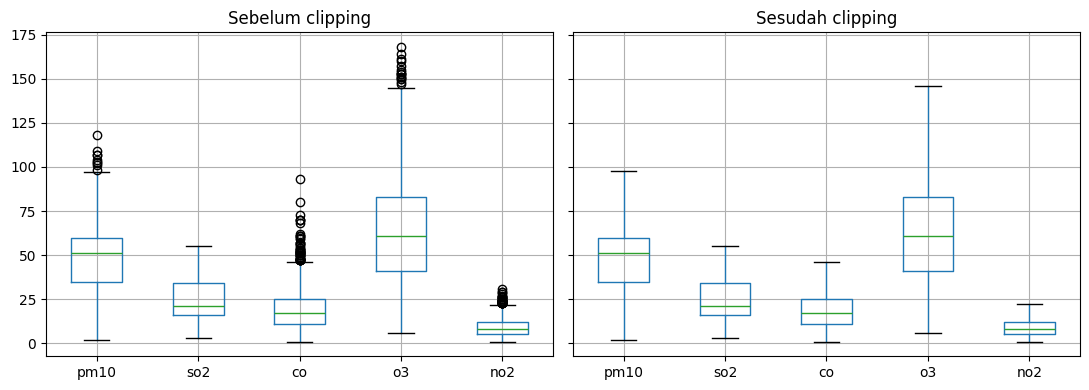

In [17]:
df_sebelum_clip = df[polutan].copy()

for kolom in polutan:
    bawah, atas = batas[kolom]
    df[kolom] = df[kolom].clip(bawah, atas)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
df_sebelum_clip.boxplot(ax=axes[0])
axes[0].set_title("Sebelum clipping")
df[polutan].boxplot(ax=axes[1])
axes[1].set_title("Sesudah clipping")
plt.tight_layout()
plt.show()

##12. Feature Engineering
Kode ini digunakan untuk membuat fitur baru dari data yang sudah ada, yaitu bulan, hari dalam minggu, penanda akhir pekan, musim, dan kode singkat stasiun. Fitur-fitur ini dapat membantu analisis pola kualitas udara berdasarkan waktu dan lokasi pemantauan.

In [18]:
df["bulan"] = df["tanggal"].dt.month
df["hari_minggu"] = df["tanggal"].dt.dayofweek          # 0 = Senin
df["akhir_pekan"] = (df["hari_minggu"] >= 5).astype(int)
df["musim"] = np.where(df["bulan"].isin([11, 12, 1, 2, 3, 4]), "HUJAN", "KEMARAU")

# kode stasiun singkat, mis. "DKI1 (BUNDERAN HI)" -> "DKI1"
df["stasiun_kode"] = df["stasiun"].str.extract(r"^(DKI\d)")[0]

df[["tanggal", "bulan", "hari_minggu", "akhir_pekan", "musim", "stasiun_kode"]].head()

,tanggal,bulan,hari_minggu,akhir_pekan,musim,stasiun_kode
0,2017-01-01,1,6,1,HUJAN,DKI1
1,2017-01-02,1,0,0,HUJAN,DKI1
2,2017-01-03,1,1,0,HUJAN,DKI1
3,2017-01-04,1,2,0,HUJAN,DKI1
4,2017-01-05,1,3,0,HUJAN,DKI1


##13. Encoding Variabel Kategorikal
Kode ini digunakan untuk mengubah data kategorikal menjadi bentuk numerik menggunakan mapping dan One-Hot Encoding. Kolom kategori diubah menjadi kode angka, sedangkan kolom stasiun_kode, musim, dan critical diubah menjadi beberapa kolom bernilai 0 dan 1 agar dapat digunakan dalam analisis data.

In [19]:
urutan_kategori = {"BAIK": 0, "SEDANG": 1, "TIDAK SEHAT": 2, "SANGAT TIDAK SEHAT": 3}
df["kategori_kode"] = df["kategori"].map(urutan_kategori)

df_enc = pd.get_dummies(df, columns=["stasiun_kode", "musim", "critical"],
                        prefix=["stasiun", "musim", "critical"], dtype=int)

print("Kolom setelah encoding:")
print(df_enc.columns.tolist())

Kolom setelah encoding:
['periode_data', 'tanggal', 'stasiun', 'pm10', 'so2', 'co', 'o3', 'no2', 'max_ispu', 'kategori', 'bulan', 'hari_minggu', 'akhir_pekan', 'kategori_kode', 'stasiun_DKI1', 'stasiun_DKI2', 'stasiun_DKI3', 'stasiun_DKI4', 'stasiun_DKI5', 'musim_HUJAN', 'musim_KEMARAU', 'critical_CO', 'critical_NO2', 'critical_O3', 'critical_PM10', 'critical_SO2']


##14. Scaling Data
Kode ini digunakan untuk menyamakan rentang nilai pada kolom polutan menggunakan metode Min-Max Scaling. Nilai polutan diubah ke rentang 0 sampai 1 dan disimpan dalam kolom baru dengan akhiran _scaled, sehingga nilai asli tetap tersimpan.

In [20]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
kolom_scaled = [k + "_scaled" for k in polutan]
df_enc[kolom_scaled] = scaler.fit_transform(df_enc[polutan])

df_enc[polutan + kolom_scaled].describe().round(3)

,pm10,so2,co,o3,no2,pm10_scaled,so2_scaled,co_scaled,o3_scaled,no2_scaled
count,1795.000,1795.000,1795.000,1795.000,1795.000,1795.000,1795.000,1795.000,1795.000,1795.000
mean,47.865,26.325,18.971,63.579,8.855,0.480,0.449,0.399,0.411,0.365
std,18.846,13.437,10.852,29.306,5.025,0.197,0.258,0.241,0.209,0.234
min,2.000,3.000,1.000,6.000,1.000,0.000,0.000,0.000,0.000,0.000
25%,35.000,16.000,11.000,41.000,5.000,0.346,0.250,0.222,0.250,0.186
50%,51.000,21.000,17.000,61.000,8.000,0.513,0.346,0.356,0.393,0.326
75%,60.000,34.000,25.000,83.000,12.000,0.607,0.596,0.533,0.550,0.512
max,97.500,55.000,46.000,146.000,22.500,1.000,1.000,1.000,1.000,1.000


##15. Analisis Distribusi Kelas
Kode ini digunakan untuk menghitung jumlah dan persentase setiap kategori ISPU, seperti BAIK, SEDANG, dan TIDAK SEHAT. Hasilnya ditampilkan dalam bentuk tabel dan diagram batang untuk melihat persebaran data pada setiap kategori.

kategori
SEDANG         1121
BAIK            476
TIDAK SEHAT     198
Name: count, dtype: Int64

kategori
SEDANG         62.5 %
BAIK           26.5 %
TIDAK SEHAT    11.0 %
Name: count, dtype: object


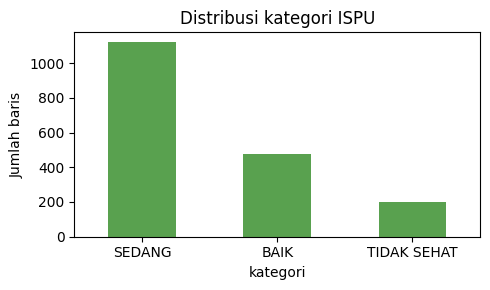

In [21]:
dist = df_enc["kategori"].value_counts()
print(dist)
print()
print((dist / dist.sum() * 100).round(1).astype(str) + " %")

dist.plot(kind="bar", figsize=(5, 3), color="#59A14F")
plt.title("Distribusi kategori ISPU")
plt.ylabel("Jumlah baris")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

##16. Evaluasi dan Penyimpanan Hasil Preprocessing
Kode ini digunakan untuk membandingkan kondisi dataset sebelum dan sesudah preprocessing, meliputi jumlah baris, jumlah kolom, dan sel kosong. Setelah itu, dataset hasil preprocessing disimpan dalam format CSV dengan nama ispu_2017_preprocessed.csv dan diunduh agar dapat digunakan kembali.

In [22]:
ringkasan_akhir = pd.DataFrame({
    "Sebelum": [df_raw.shape[0], df_raw.shape[1], int((df_raw == "---").sum().sum()
                                                         + df_raw.isna().sum().sum())],
    "Sesudah": [df_enc.shape[0], df_enc.shape[1], int(df_enc.isna().sum().sum())],
}, index=["Jumlah baris", "Jumlah kolom", "Sel kosong / placeholder"])
ringkasan_akhir

,Sebelum,Sesudah
Jumlah baris,1825,1795
Jumlah kolom,11,31
Sel kosong / placeholder,497,0


In [23]:
df_enc.to_csv("ispu_2017_preprocessed.csv", index=False)
print("Tersimpan:", df_enc.shape)

try:
    from google.colab import files
    files.download("ispu_2017_preprocessed.csv")
except ImportError:
    pass

Tersimpan: (1795, 31)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>